# HUMAN RIBOFLOW FILTER: v2 vs v3 ALIGNMENTS

Here we compare how the v2 and v3 filters handle real reads. `compare_v2_and_v3.ipynb` compares
their sequences.

We aligned the same reads to both filters with the RiboFlow filter step (`bowtie2 -L 15 --norc`).
There are four libraries: two GEO samples (GSM1606107 and GSM1606108), with two runs each (`v4.1`
and `v4.2`).

In [1]:
import os, re, subprocess
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

REPO = "../../../.."   # repo root
CMP = f"{REPO}/filter/human/v3/comparison"
VERSIONS = ("v2", "v3")
LIBS = sorted(f.removesuffix(".filter.log") for f in os.listdir(f"{CMP}/v3") if f.endswith(".filter.log"))
LIBS

['GSM1606107_v4.1', 'GSM1606107_v4.2', 'GSM1606108_v4.1', 'GSM1606108_v4.2']

## Alignment rates

From the Bowtie2 logs. `removed %` is the percentage of input reads that align to the filter.

In [2]:
def read_log(path):
    text = open(path).read()
    n = lambda pattern: int(re.search(pattern, text).group(1))
    return {"reads": n(r"(\d+) reads; of these"),
            "unaligned": n(r"(\d+) \([\d.]+%\) aligned 0 times"),
            "exactly 1": n(r"(\d+) \([\d.]+%\) aligned exactly 1 time"),
            ">1": n(r"(\d+) \([\d.]+%\) aligned >1 times")}

logs = pd.DataFrame([{"library": lib, "version": v, **read_log(f"{CMP}/{v}/{lib}.filter.log")}
                     for lib in LIBS for v in VERSIONS]).set_index(["library", "version"])
logs["removed %"] = (100 * (1 - logs.unaligned / logs.reads)).round(2)
logs

reads  unaligned  exactly 1        >1  removed %
library         version                                                     
GSM1606107_v4.1 v2       64116298    9907225     474381  53734692      84.55
                v3       64116298    9724648     228487  54163163      84.83
GSM1606107_v4.2 v2       45125998    6125942     311383  38688673      86.42
                v3       45125998    6015239     137905  38972854      86.67
GSM1606108_v4.1 v2       45229300   12741031     552126  31936143      71.83
                v3       45229300   12386359     377965  32464976      72.61
GSM1606108_v4.2 v2       57795858    7217021     385599  50193238      87.51
                v3       57795858    7022349     208361  50565148      87.85

In [3]:
rates = logs["removed %"].unstack()
rates["Δ (pp)"] = rates.v3 - rates.v2
rates["extra reads removed"] = logs.unaligned.xs("v2", level=1) - logs.unaligned.xs("v3", level=1)
rates

version,v2,v3,Δ (pp),extra reads removed
library,,,,
GSM1606107_v4.1,84.55,84.83,0.28,182577
GSM1606107_v4.2,86.42,86.67,0.25,110703
GSM1606108_v4.1,71.83,72.61,0.78,354672
GSM1606108_v4.2,87.51,87.85,0.34,194672


v3 removes 0.25 to 0.78 percentage points more reads in each library.

Fewer reads align exactly once in v3. v3 has more copies of some sequences (five rDNA
units, 17 5S genes, repeated tRNA genes), so a read with one target in v2 can have several in v3.
This does not change the filter, because any alignment removes the read.

## Reads per category

Each BAM has one record per aligned read. When a read aligns equally well to several targets,
Bowtie2 picks one at random.

In [ ]:
def category(ref):
    if "|" in ref:                                   # v3: source|accession|symbol
        source, _, symbol = ref.split("|")
        if source == "ncbi_mt":
            return "mt rRNA" if "RNR" in symbol else "mt tRNA"
        return {"ncbi_rRNA": "nuclear rRNA", "gtrnadb_tRNA": "nuclear tRNA",
                "v2": "snRNA pseudogene / repeat"}[source]
    if ref.startswith("rRNA"):       return "nuclear rRNA"
    if ref.startswith("hg19_tRNAs"): return "nuclear tRNA"
    return "snRNA pseudogene / repeat"

CATEGORIES = ["nuclear rRNA", "nuclear tRNA", "mt rRNA", "mt tRNA", "snRNA pseudogene / repeat"]

def reads_per_reference(bam):
    if not os.path.exists(bam + ".bai"):
        subprocess.run(["samtools", "index", "-@", "4", bam], check=True)
    out = subprocess.run(["samtools", "idxstats", bam], capture_output=True, text=True, check=True).stdout
    counts = {ref: int(mapped) for ref, _, mapped, _ in (line.split("\t") for line in out.splitlines()) if ref != "*"}
    return pd.Series(counts)

ref_counts = {(lib, v): reads_per_reference(f"{CMP}/{v}/{lib}.filter.bam") for lib in LIBS for v in VERSIONS}

In [5]:
by_category = pd.DataFrame({key: s.groupby(category).sum() for key, s in ref_counts.items()}).reindex(CATEGORIES).fillna(0).astype(int)
by_category.columns.names = ["library", "version"]
by_category

library                   GSM1606107_v4.1           GSM1606107_v4.2            \
version                                v2        v3              v2        v3   
nuclear rRNA                     52961558  52960655        38278870  38278089   
nuclear tRNA                      1235399   1232174          714701    712858   
mt rRNA                                 0    176133               0    106914   
mt tRNA                                 0     10572               0      6413   
snRNA pseudogene / repeat           12116     12116            6485      6485   

library                   GSM1606108_v4.1           GSM1606108_v4.2            
version                                v2        v3              v2        v3  
nuclear rRNA                     31684732  31682070        50141046  50138945  
nuclear tRNA                       797246    796360          434834    434283  
mt rRNA                                 0    346779               0    190989  
mt tRNA                                 0     11441               0      6335  
snRNA pseudogene / repeat            6291      6291            2957      2957

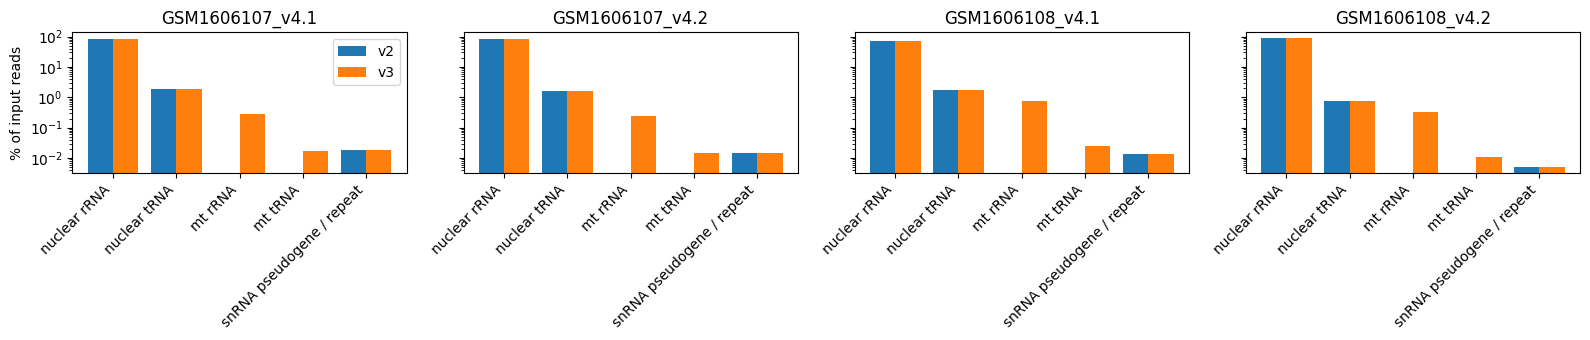

In [6]:
pct = 100 * by_category / logs.reads
fig, axes = plt.subplots(1, len(LIBS), figsize=(4 * len(LIBS), 3.5), sharey=True)
x = np.arange(len(CATEGORIES))
for ax, lib in zip(axes, LIBS):
    for i, v in enumerate(VERSIONS):
        ax.bar(x + (i - 0.5) * 0.4, pct[(lib, v)], width=0.4, label=v)
    ax.set_xticks(x, CATEGORIES, rotation=45, ha="right")
    ax.set_yscale("log"); ax.set_title(lib)
axes[0].set_ylabel("% of input reads"); axes[0].legend()
plt.tight_layout()

### Mitochondrial references (new in v3)

Reads per mitochondrial reference in v3. MT-RNR1 and MT-RNR2 are the 12S and 16S rRNAs. The MT-T
genes are tRNAs, named by amino acid (MT-TP is tRNA-Pro, MT-TM is tRNA-Met, and so on).

In [7]:
mt = pd.DataFrame({lib: ref_counts[(lib, "v3")] for lib in LIBS})
mt = mt[mt.index.str.startswith("ncbi_mt|")].fillna(0).astype(int)
mt.index = mt.index.str.split("|").str[2]
mt.sort_values(LIBS[0], ascending=False)

,GSM1606107_v4.1,GSM1606107_v4.2,GSM1606108_v4.1,GSM1606108_v4.2
MT-RNR2,144866,89271,302232,166638
MT-RNR1,31267,17643,44547,24351
MT-TV,3499,2165,3614,2013
MT-TF,2186,1223,2974,1502
MT-TP,1790,1198,773,433
MT-TM,773,486,1662,967
MT-TN,521,287,658,389
MT-TI,254,115,228,134
MT-TS2,182,118,141,73
MT-TL1,167,101,54,50


## Which reads changed

A read is *newly removed* if it passes v2 but aligns to v3. It is *newly kept* if it aligns to v2
but passes v3. 

We find these reads by comparing the unaligned FASTQs. Then we look up where they
aligned: in the v3 BAM for newly removed reads, and in the v2 BAM for newly kept reads.

In [8]:
def unaligned_names(v, lib):
    cmd = f"gzip -dc {CMP}/{v}/{lib}.unaligned.filter.fastq.gz | awk 'NR % 4 == 1 {{print substr($1, 2)}}'"
    return set(subprocess.run(cmd, shell=True, capture_output=True, text=True, check=True).stdout.split())

def lookup(names, bam, tmp):
    with open(tmp, "w") as fh:
        fh.write("\n".join(names) + "\n")
    cmd = (f"samtools view {bam} | awk -v OFS='\\t' "
           f"'NR == FNR {{keep[$1]; next}} ($1 in keep) {{print $1, $3, length($10)}}' {tmp} -")
    out = subprocess.run(cmd, shell=True, capture_output=True, text=True, check=True).stdout
    return pd.DataFrame([line.split("\t") for line in out.splitlines()], columns=["read", "ref", "length"])

cache = f"{CMP}/changed_reads.tsv.gz"
if os.path.exists(cache):
    changed = pd.read_csv(cache, sep="\t")
else:
    parts = []
    for lib in LIBS:
        pass_v2, pass_v3 = unaligned_names("v2", lib), unaligned_names("v3", lib)
        for change, names, v in (("newly removed", pass_v2 - pass_v3, "v3"),
                                 ("newly kept",    pass_v3 - pass_v2, "v2")):
            df = lookup(names, f"{CMP}/{v}/{lib}.filter.bam", f"{CMP}/.names.tmp")
            assert len(df) == len(names), (lib, change, len(df), len(names))
            parts.append(df.assign(library=lib, change=change))
        del pass_v2, pass_v3
    os.remove(f"{CMP}/.names.tmp")
    changed = pd.concat(parts, ignore_index=True)
    changed.to_csv(cache, sep="\t", index=False)

changed["length"] = changed.length.astype(int)
changed["category"] = changed.ref.map(category)
changed.groupby(["library", "change"]).size().unstack()

change,newly kept,newly removed
library,,
GSM1606107_v4.1,4604,187181
GSM1606107_v4.2,3012,113715
GSM1606108_v4.1,4104,358776
GSM1606108_v4.2,3028,197700


The difference between the two columns equals `extra reads removed` in the table above.

In [9]:
changed.groupby(["change", "category"]).size().unstack(0).fillna(0).astype(int)

change,newly kept,newly removed
category,,
mt rRNA,0,820815
mt tRNA,0,34395
nuclear rRNA,7979,1532
nuclear tRNA,6769,630


### Top references

In [10]:
top = lambda change: changed[changed.change == change].ref.value_counts().head(15).rename("reads").to_frame()
top("newly removed")

,reads
ref,
ncbi_mt|NC_012920.1:1671-3229|MT-RNR2,703007
ncbi_mt|NC_012920.1:648-1601|MT-RNR1,117808
ncbi_mt|NC_012920.1:1602-1670|MT-TV,11291
ncbi_mt|NC_012920.1:577-647|MT-TF,7885
ncbi_mt|NC_012920.1:16023-15956|MT-TP,4194
ncbi_mt|NC_012920.1:4402-4469|MT-TM,3888
ncbi_mt|NC_012920.1:5729-5657|MT-TN,1855
ncbi_mt|NC_012920.1:4263-4331|MT-TI,731
ncbi_mt|NC_012920.1:15888-15953|MT-TT,574


In [11]:
top("newly kept")

,reads
ref,
rRNA5,5671
hg19_tRNAs_chr6.tRNA85-PseudoTTC,2447
rRNA28,2263
hg19_tRNAs_chr5.tRNA22-AspGTC,1106
hg19_tRNAs_chr8.tRNA3-GluCTC,984
hg19_tRNAs_chr2.tRNA12-PseudoCTC,600
hg19_tRNAs_chr1.tRNA64-GluTTC,182
hg19_tRNAs_chr1.tRNA100-PseudoGAA,105
hg19_tRNAs_chr1.tRNA137-Pseudo???,103


### Read lengths

Most ribosome footprints are 26 to 34 nt. Reads of that length that pass the filter are counted as
footprints.

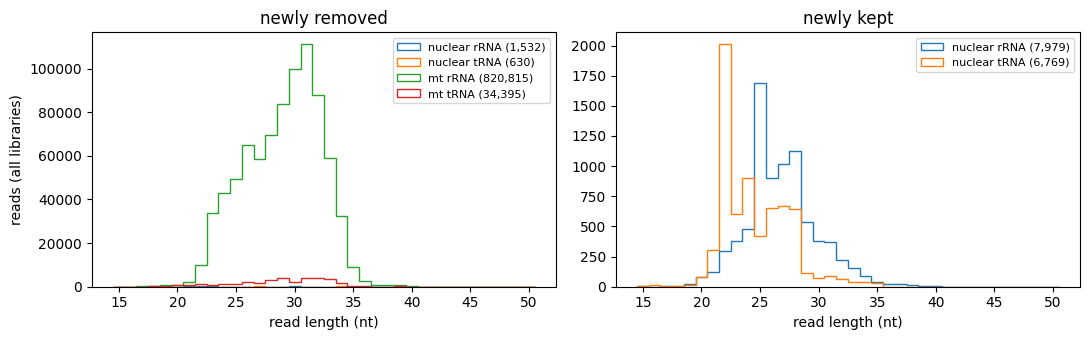

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
bins = np.arange(15, 52) - 0.5
for ax, change in zip(axes, ("newly removed", "newly kept")):
    sub = changed[changed.change == change]
    for cat in CATEGORIES:
        lengths = sub.length[sub.category == cat]
        if len(lengths):
            ax.hist(lengths, bins=bins, histtype="step", label=f"{cat} ({len(lengths):,})")
    ax.set_title(change); ax.set_xlabel("read length (nt)"); ax.legend(fontsize=8)
axes[0].set_ylabel("reads (all libraries)")
plt.tight_layout()

## Summary

Over the four libraries, v3 removes 857,372 reads that v2 kept and keeps 14,748 reads that v2
removed. That is 842,624 more reads removed, or 0.25 to 0.78% of the input per library.

Almost all of the newly removed reads come from the mitochondrial sequences. 855,210 of them
(99.7%) align to mitochondrial references, mostly MT-RNR2 (703,007) and MT-RNR1 (117,808). 81% are
26 to 34 nt, the same length as footprints. With v2, these reads went on to the transcriptome.

mt-rRNA is still only 0.2 to 0.7% of the input, compared with 70 to 85% for nuclear rRNA.

Nuclear rRNA and tRNA counts change by less than 0.4% per library.

Most newly kept reads align to v2 sequences that are not in v3: the v2 5S (`rRNA5`, 5,671 reads)
and 28S (`rRNA28`, 2,263) sequences, and hg19 tRNA pseudogenes that are not in the GtRNAdb
high-confidence set (`tRNA85-PseudoTTC`, 2,447). This is less than 0.01% of the input.

The snRNA pseudogene and repeat sequences are the same in both filters and get the same reads.